# Example 4: emulator vs. N-body halo statistics, from many simulations

This notebook compares halo statistics from 1000 emulated simulations with 1000 Quijote N-body simulations, at the
same cosmology and resolution (512³ particles in a 1 Gpc/*h* box, z = 0):

- power spectra of the halo density $h$ and of the halo momentum, split into its gradient mode $q$ and curl mode $c$;
- the correlation coefficient between $h$ and $q$, and the "residual" field $r = h - b\,(k/faH)\,q$, from which the
  velocity-inferred density has been subtracted;
- the covariance of $P_{hh}(k)$.

## Matching the halo samples

**The comparison is only meaningful if the two catalogs contain equivalent halos.** Every statistic above depends on
which halos are selected, mostly through their large-scale bias $b$ and their number density $\bar n$: on large
scales $P_{hh} \approx b^2 P_m + 1/\bar n$, so a 2% difference in $b$ changes $P_{hh}$ by 4%. Such a difference would
look like an error in the emulator's clustering, when it only means that the two halo finders select slightly
different halos. So we match the two samples, in two steps:

1. **The FoF linking length.** The emulator's catalogs use a friends-of-friends linking length of **0.18** (in units
   of the mean interparticle spacing), not the conventional **0.2** of Quijote's catalogs. The emulator's halos are
   slightly more diffuse than N-body halos, so with 0.2 their masses would come out 6–7% higher than Quijote's. With
   0.18, the emulator's mass function agrees with that of Quijote's FoF(0.2) halos to within 3% over most of the
   mass range, and to ~5% for the smallest halos (see `01_halo_catalog.ipynb`, and Appendix A). This is already a
   matching of the two samples, by mass.
2. **The bias and the number density.** Even so, the emulator's halos with ≥ 20 particles are less biased than
   Quijote's ($b = 1.339$ vs. $1.386$ at $k < 0.02$ Mpc$^{-1}$), and 3% fewer. To match the bias, we **throw out the
   emulator's least massive halos: 12.7% of them** (all the halos with 20 or 21 particles, and 90% of those with 22).
   The emulator then has 15.5% fewer halos than Quijote, so we **throw out 15.5% of Quijote's halos, chosen at
   random**. A random dilution doesn't change the bias; it only adds shot noise. The matched samples have the same
   bias ($b = 1.38$) and the same number of halos (344,000 per box).

The matching makes a large difference: without it, the emulator's $P_{hh}$ is ~6% lower than Quijote's on large
scales; with it, the two agree to 1%. The main results below are for the matched samples. **Appendix A** shows the
results without matching (all halos with ≥ 20 particles), and the mass functions.

The notebook only makes plots, from power spectra computed beforehand (it runs in under a minute). Make them with
`02_make_halo_catalog.py` (GPU) and `03_halo_power_spectra.py` (CPU, needs
[kszx](https://github.com/kmsmith137/kszx)), e.g. as batch jobs (see `README.md`):

```bash
python 02_make_halo_catalog.py 0 1000 --outdir EMU_DIR                      # 37 s per catalog on an H200
python -c "import kszx; kszx.quijote.download('fiducial', 1000, products=('halos',))"    # 34 MB per catalog
python 03_halo_power_spectra.py match --emulator-dir EMU_DIR --out SPECTRA_DIR/matching.json   # ~10 minutes
python 03_halo_power_spectra.py compute emulator 0 1000 --outdir SPECTRA_DIR --emulator-dir EMU_DIR \
    --matching SPECTRA_DIR/matching.json                                    # 15-30 s per catalog
python 03_halo_power_spectra.py compute quijote 0 1000 --outdir SPECTRA_DIR --matching SPECTRA_DIR/matching.json
```

## Parameters

In [1]:
import os

SPECTRA_DIR = '/mnt/beegfs/kmsmith/nbody_emulator/spectra'   # --outdir of '03_halo_power_spectra.py compute'
MATCHING = os.path.join(SPECTRA_DIR, 'matching.json')       # from '03_halo_power_spectra.py match' (optional here)
KFIT = 0.02          # the bias b of the residual field is fit at k < KFIT [Mpc^-1]
KMAX_PLOT = 0.6      # largest k in the plots of the spectra [Mpc^-1]
COV_WIDTH = 3        # covariance of P_hh: bins of width COV_WIDTH k_f (k_f = 2 pi / L, the fundamental frequency) ...
COV_KMAX = 0.3       # ... up to k = COV_KMAX [Mpc^-1]

## Reading the power spectra

`03_halo_power_spectra.py compute` writes one file per catalog, `pk_{kind}_{i}.npz`, with the spectra of all the
halos (sample `'all'`) and of the matched subsample (`'matched'`), and the number of halos with each particle number.
`load()` stacks them.

In [2]:
import glob, json, re
import numpy as np
import matplotlib.pyplot as plt

SPECTRA = ('hh', 'hq', 'qq', 'cc', 'hv', 'vv')
NPART_EDGES = np.unique(np.round(np.geomspace(20, 1e5, 36))) - 0.5      # bins of particle number, for the mass function


def load(kind):
    """Returns {sample: dict of arrays}: P[catalog, spectrum, kbin] for the spectra in SPECTRA, shot_noise[catalog,
    spectrum], noise_vv[catalog, kbin], nbar[catalog], ..., and the k-bins (k, counts), the same for all catalogs.
    The 'all' sample also has npart_hist[catalog, bin]: the number of halos in the bins NPART_EDGES."""
    files = glob.glob(os.path.join(SPECTRA_DIR, f'pk_{kind}_*.npz'))
    files.sort(key=lambda f: int(re.search(r'_(\d+)\.npz$', f).group(1)))
    if not files:
        raise RuntimeError(f'no files {SPECTRA_DIR}/pk_{kind}_*.npz: see 03_halo_power_spectra.py')
    keys = ('P', 'shot_noise', 'noise_vv', 'nbar', 'nhalos', 'catalog_index', 'npart_hist')
    out = {}
    for f in files:
        with np.load(f) as z:
            assert tuple(z['spectra']) == SPECTRA
            for s in z['samples']:
                if s not in out:
                    out[s] = dict(k=z['k'], counts=z['counts'], box_size=float(z['box_size']), faH=float(z['faH']),
                                  particle_mass=float(z['particle_mass']), selection=str(z[f'selection_{s}']),
                                  **{key: [] for key in keys})
                d = out[s]
                assert np.array_equal(z['k'], d['k']) and (str(z[f'selection_{s}']) == d['selection']), f
                for key in ('P', 'shot_noise', 'noise_vv', 'nbar', 'nhalos'):
                    d[key].append(z[f'{key}_{s}'])
                d['catalog_index'].append(int(z['catalog_index']))
                if s == 'all':
                    d['npart_hist'].append(np.histogram(z['npart_values'], NPART_EDGES, weights=z['npart_counts'])[0])
    for d in out.values():
        d.update({key: np.array(d[key]) for key in keys})
    return out


data = {kind: load(kind) for kind in ('emulator', 'quijote')}
L = data['quijote']['all']['box_size']                      # box size [Mpc]
for sample in ('all', 'matched'):
    for kind in ('emulator', 'quijote'):
        d = data[kind].get(sample)
        if d is not None:
            print(f'{sample:8s} {kind:8s}: {len(d["P"])} catalogs, {d["nhalos"].mean():.0f} halos per box, '
                  f'selection {d["selection"]}')
k = data['quijote']['all']['k']
print(f'{len(k)} k-bins of width k_f = {2 * np.pi / L:.5f} / Mpc, up to {k[-1]:.3f} / Mpc')

all      emulator: 1000 catalogs, 393517 halos per box, selection {"min_npart": 20, "boundary_fraction": 0.0, "keep_fraction": 1.0}
all      quijote : 1000 catalogs, 406754 halos per box, selection {"min_npart": 20, "boundary_fraction": 0.0, "keep_fraction": 1.0}
matched  emulator: 1000 catalogs, 343584 halos per box, selection {"min_npart": 23, "boundary_fraction": 0.1026, "keep_fraction": 1.0}
matched  quijote : 1000 catalogs, 343651 halos per box, selection {"min_npart": 20, "boundary_fraction": 0.0, "keep_fraction": 0.8449}
189 k-bins of width k_f = 0.00422 / Mpc, up to 0.797 / Mpc


## Fields and power spectra

For a catalog of $N$ halos at positions $\mathbf x_i$, with velocities $\mathbf v_i$ in units of $c$, in a box of
volume $V$ with $\bar n = N/V$, the fields are:

- the halo number density contrast,
  $$h(\mathbf k) = \frac{1}{\bar n} \sum_i e^{-i\mathbf k\cdot\mathbf x_i}$$
- the halo momentum density $(1 + \delta_h)\,\mathbf v$,
  $$\mathbf p(\mathbf k) = \frac{1}{\bar n} \sum_i \mathbf v_i\, e^{-i\mathbf k\cdot\mathbf x_i}$$
- its gradient (longitudinal) mode, which is $q = (faH/c)\,\delta / k$ in linear theory (so $P_{hq} > 0$),
  $$q(\mathbf k) = -i\,\hat{\mathbf k}\cdot\mathbf p(\mathbf k)$$
- its curl (transverse) mode, which has two components ($P_{cc}$ is the power of both),
  $$\mathbf c(\mathbf k) = \hat{\mathbf k}\times\mathbf p(\mathbf k)$$
- the velocity-inferred density, which by the continuity equation is the matter density $\delta_m$ in linear theory,
  $$v(\mathbf k) = \frac{k\, q(\mathbf k)}{faH/c}$$

The Fourier conventions are those of kszx: $\langle f(\mathbf k)\, g(\mathbf k')^* \rangle = V\, P_{fg}(k)\,
\delta_{\mathbf k \mathbf k'}$. `03_halo_power_spectra.py` assigns the halos to a 512³ grid with kszx's cubic kernel,
divides the kernel out in Fourier space, and averages the spectra over the modes in bins
$[(j+\frac12)k_f, (j+\frac32)k_f)$, where $k_f = 2\pi/L$. Shot noise is not subtracted: its expected value is
$1/\bar n$ for $P_{hh}$, $\langle v^2 \rangle / 3\bar n$ for $P_{qq}$, and $2\langle v^2 \rangle / 3\bar n$ for $P_{cc}$.

## How the samples are matched

`03_halo_power_spectra.py match` chooses the matched samples (see the introduction), from 300 simulations of each kind:

1. The bias $b$ is measured as the coefficient that minimizes the power of $r = h - b\,v$ at $k <$ `KFIT`:
   $$b = \frac{\sum \mathrm{Re}(h\, v^*)}{\sum |v|^2},$$
   summed over the modes and the simulations. Every mode's density fluctuation appears in both sums, so sample
   variance cancels: one box gives $b$ to ~1.5%, 300 boxes to ~0.1%.
2. The emulator's minimum particle number is raised until its $b$ matches Quijote's (all halos with ≥ 20 particles).
   The threshold is made continuous by also keeping a random fraction of the halos just below it.
3. The more abundant of the two samples (Quijote's) is then diluted at random to the other's number density.

The table shows $b$ and the number of halos as the emulator's threshold is raised.

In [3]:
if os.path.exists(MATCHING):
    with open(MATCHING) as f:
        m = json.load(f)
    print(f'From {m["nboxes"]} simulations of each kind (b fit at k < {m["kfit"]} / Mpc):')
    for kind in ('quijote', 'emulator'):
        for row in m['table'][kind]:
            print(f'  {kind:8s} npart >= {row["min_npart"]}:  b = {row["b"]:.4f} ± {row["b_err"]:.4f},  '
                  f'{row["nhalos"]:.0f} halos per box')
    print(f'Matched samples: b = {m["b"]:.4f}, {m["nhalos"]:.0f} halos per box')
    for kind in ('emulator', 'quijote'):
        print(f'  {kind:8s} {m[kind]}')

print('\nIn the 1000 simulations of each kind:')
for kind in ('emulator', 'quijote'):
    n_all, n_matched = data[kind]['all']['nhalos'].mean(), data[kind]['matched']['nhalos'].mean()
    print(f'  {kind:8s}: {n_all:.0f} halos per box, {n_matched:.0f} matched: {100 * (1 - n_matched / n_all):.1f}% thrown out')

From 300 simulations of each kind (b fit at k < 0.02 / Mpc):
  quijote  npart >= 20:  b = 1.3806 ± 0.0011,  406700 halos per box
  emulator npart >= 20:  b = 1.3382 ± 0.0011,  393578 halos per box
  emulator npart >= 21:  b = 1.3531 ± 0.0010,  374762 halos per box
  emulator npart >= 22:  b = 1.3675 ± 0.0011,  357678 halos per box
  emulator npart >= 23:  b = 1.3821 ± 0.0010,  342027 halos per box
  emulator npart >= 24:  b = 1.3964 ± 0.0011,  327713 halos per box
  emulator npart >= 25:  b = 1.4100 ± 0.0011,  314493 halos per box
  emulator npart >= 26:  b = 1.4237 ± 0.0011,  302276 halos per box
Matched samples: b = 1.3806, 343632 halos per box
  emulator {'min_npart': 23, 'boundary_fraction': 0.1026, 'keep_fraction': 1.0}
  quijote  {'min_npart': 20, 'boundary_fraction': 0.0, 'keep_fraction': 0.8449}

In the 1000 simulations of each kind:
  emulator: 393517 halos per box, 343584 matched: 12.7% thrown out
  quijote : 406754 halos per box, 343651 matched: 15.5% thrown out


## Plotting functions

In [4]:
NAMES = ('hh', 'hq', 'qq', 'cc')
LABELS = {'hh': r'$P_{hh}$  (halo density)', 'hq': r'$P_{hq}$  (density $\times$ gradient mode)',
          'qq': r'$P_{qq}$  (momentum, gradient mode)', 'cc': r'$P_{cc}$  (momentum, curl mode)'}
UNITS = {'hh': r'Mpc$^3$', 'hq': r'Mpc$^3$ $(v/c)$', 'qq': r'Mpc$^3$ $(v/c)^2$', 'cc': r'Mpc$^3$ $(v/c)^2$'}
COLORS = {'quijote': '#2a78d6', 'emulator': '#eb6834'}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'


def rebin(d, nfine=6, dlogk=0.06):
    """Combines the bins of width k_f: the first nfine as they are, then bins of width dlogk in log10(k).
    Returns k, P[catalog, spectrum, bin] (mode-weighted means)."""
    k, n = d['k'], d['counts'].astype(float)
    groups, j = [], 0
    while j < len(k):
        hi = j + 1
        while (j >= nfine) and (hi < len(k)) and (np.log10(k[hi] / k[j]) < dlogk):
            hi += 1
        groups.append(slice(j, hi))
        j = hi
    kb = np.array([np.sum(n[g] * k[g]) / np.sum(n[g]) for g in groups])
    Pb = np.stack([np.sum(n[g] * d['P'][..., g], axis=-1) / np.sum(n[g]) for g in groups], axis=-1)
    return kb, Pb


def style(ax):
    ax.grid(True, which='major', color=GRID, lw=0.6)
    ax.tick_params(colors=INK2)
    for sp in ax.spines.values():
        sp.set_color('#b5b4ae')


def ratio_panel(axr, k, m_emu, e_emu, m_qui, e_qui, difference=False):
    if difference:
        x, ex, ref = m_emu - m_qui, np.hypot(e_emu, e_qui), 0
    else:
        x, ex, ref = m_emu / m_qui, np.abs(m_emu / m_qui) * np.hypot(e_emu / m_emu, e_qui / m_qui), 1
    axr.axhline(ref, color=INK2, lw=1)
    axr.fill_between(k, x - ex, x + ex, color=COLORS['emulator'], alpha=0.3, lw=0)
    axr.plot(k, x, color=COLORS['emulator'], lw=1.5, marker='o', ms=3)
    return x, ex


def plot_spectra(emu, qui, title, kmax=KMAX_PLOT):
    """P_hh, P_hq, P_qq, P_cc: means over the simulations, and their ratio (errors: of the means)."""
    k, Pe = rebin(emu)
    _, Pq = rebin(qui)
    s = k < kmax
    fig = plt.figure(figsize=(12.5, 9.5))
    gs = fig.add_gridspec(4, 2, height_ratios=[2.4, 1, 2.4, 1], hspace=0.08, wspace=0.28, left=0.08, right=0.98, top=0.93, bottom=0.07)
    fig.suptitle(title, color=INK, fontsize=13)
    for n, name in enumerate(NAMES):
        r, c = 2 * (n // 2), n % 2
        ax, axr = fig.add_subplot(gs[r, c]), fig.add_subplot(gs[r + 1, c])
        mq, eq = Pq[:, n].mean(0), Pq[:, n].std(0, ddof=1) / np.sqrt(len(Pq))
        me, ee = Pe[:, n].mean(0), Pe[:, n].std(0, ddof=1) / np.sqrt(len(Pe))
        ax.fill_between(k[s], (mq - eq)[s], (mq + eq)[s], color=COLORS['quijote'], alpha=0.35, lw=0)
        ax.plot(k[s], mq[s], color=COLORS['quijote'], lw=2, label=f'Quijote N-body ({len(Pq)} boxes)')
        ax.errorbar(k[s], me[s], ee[s], color=COLORS['emulator'], lw=1.2, marker='o', ms=4, mec='white', mew=0.6,
                    label=f'emulator ({len(Pe)} boxes)')
        shot = qui['shot_noise'][:, n].mean()
        if shot > 0:
            ax.axhline(shot, color=INK2, lw=1, ls='--')
            ax.text(k[s][0], shot * 1.04, 'shot noise (Quijote)', color=INK2, fontsize=8.5, va='bottom')
        ax.set(xscale='log', yscale='log' if np.all(mq[s] > 0) else 'symlog')
        ax.set_ylabel(f'{LABELS[name]}\n[{UNITS[name]}]', color=INK, fontsize=10)
        ax.tick_params(labelbottom=False)
        if n == 0:
            ax.legend(frameon=False, fontsize=9.5, loc='upper right')
        x, ex = ratio_panel(axr, k[s], me[s], ee[s], mq[s], eq[s])
        axr.set(xscale='log', ylim=(min(0.9, np.min(x - ex) - 0.05), max(1.1, np.max(x + ex) + 0.05)))
        axr.set_ylabel('emulator / Quijote', color=INK, fontsize=9)
        for a in (ax, axr):
            a.set_xlim(k[0] * 0.9, kmax)
            style(a)
        if r == 2:
            axr.set_xlabel(r'$k$  [Mpc$^{-1}$]', color=INK)
        else:
            axr.tick_params(labelbottom=False)
    plt.show()


def fit_bias(d, kfit=KFIT, subtract_noise=False):
    """b in r = h - b v, minimizing the power of r at k < kfit (pooled over the simulations), and its error.
    With subtract_noise=True, the momentum shot noise is subtracted from sum |v|^2 (removes the noise bias of b)."""
    m = d['k'] < kfit
    w = d['counts'][m]
    num = np.sum(w * d['P'][:, 4, m], axis=1)
    den = np.sum(w * (d['P'][:, 5, m] - (d['noise_vv'][:, m] if subtract_noise else 0)), axis=1)
    return num.sum() / den.sum(), (num / den).std(ddof=1) / np.sqrt(len(num))


def plot_residual(emu, qui, title, kfit=KFIT, kmax=KMAX_PLOT):
    """r(k) between h and q; c(k) = P_hv / P_vv (minimizes P_rr in each bin); P_rr for r = h - b v with constant b.
    Ratios are of the ensemble-mean spectra (per-box ratios are biased in bins with few modes)."""
    k, _ = rebin(emu)
    s = k < kmax
    curves, fit = {}, {}
    for kind, d in (('quijote', qui), ('emulator', emu)):
        _, P = rebin(d)
        b = fit_bias(d, kfit)
        fit[kind] = b
        Pm = P.mean(0)
        err = lambda x: x.std(0, ddof=1) / np.sqrt(len(x))
        prr = P[:, 0] - 2 * b[0] * P[:, 4] + b[0]**2 * P[:, 5]
        curves[kind] = dict(r=(Pm[1] / np.sqrt(Pm[0] * Pm[2]), err(P[:, 1] / np.sqrt(P[:, 0] * P[:, 2]))),
                            c=(Pm[4] / Pm[5], err(P[:, 4] / P[:, 5])),
                            prr=(prr.mean(0), err(prr)),
                            pmin=(Pm[0] - Pm[4]**2 / Pm[5], None),
                            shot=d['shot_noise'][:, 0].mean())
    fig = plt.figure(figsize=(16, 7.8))
    gs = fig.add_gridspec(2, 3, height_ratios=[2.4, 1], hspace=0.08, wspace=0.3, left=0.06, right=0.99, top=0.88, bottom=0.09)
    fig.suptitle(title, color=INK, fontsize=12)
    specs = [('r', r'$r(k) = P_{hq} / \sqrt{P_{hh} P_{qq}}$', 'difference'),
             ('c', r'$c(k) = P_{hv} / P_{vv}$  (minimizes $P_{rr}$ in each $k$-bin)', 'emulator / Quijote'),
             ('prr', r'$P_{rr}(k)$  [Mpc$^3$]', 'emulator / Quijote')]
    for col, (key, ylabel, rlabel) in enumerate(specs):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for kind, n in (('quijote', len(qui['P'])), ('emulator', len(emu['P']))):
            m, e = curves[kind][key]
            if kind == 'quijote':
                ax.fill_between(k[s], (m - e)[s], (m + e)[s], color=COLORS[kind], alpha=0.35, lw=0)
                ax.plot(k[s], m[s], color=COLORS[kind], lw=2, label=f'Quijote N-body ({n} boxes)')
            else:
                ax.errorbar(k[s], m[s], e[s], color=COLORS[kind], lw=1.2, marker='o', ms=3.5, mec='white', mew=0.5,
                            label=f'emulator ({n} boxes)')
            if key == 'c':
                ax.axhline(fit[kind][0], color=COLORS[kind], lw=1, ls='--')
            if key == 'prr':
                ax.plot(k[s], curves[kind]['pmin'][0][s], color=COLORS[kind], lw=1, ls=':')
                ax.axhline(curves[kind]['shot'], color=COLORS[kind], lw=0.8, ls='--', alpha=0.8)
        (me, ee), (mq, eq) = curves['emulator'][key], curves['quijote'][key]
        ratio_panel(axr, k[s], me[s], ee[s], mq[s], eq[s], difference=(key == 'r'))
        if key == 'r':
            ax.set_ylim(0, 1.02)
            axr.set_ylim(-0.04, 0.04)
            ax.legend(frameon=False, fontsize=9, loc='lower left')
        elif key == 'c':
            ax.set_ylim(-0.5, 2.2)
            axr.set_ylim(0.8, 1.2)
            ax.axvline(kfit, color=INK2, lw=0.8, ls=':')
            ax.text(kfit * 1.05, 2.1, 'fit range', color=INK2, fontsize=8.5, va='top')
            ax.text(0.04, 0.06, 'fitted b:  ' + ',  '.join(f'{name} {fit[kind][0]:.4f} ± {fit[kind][1]:.4f}'
                    for kind, name in (('quijote', 'Quijote'), ('emulator', 'emulator'))), transform=ax.transAxes, color=INK, fontsize=9)
        else:
            ax.set_yscale('log')
            axr.set_ylim(0.85, 1.25)
            ax.text(0.04, 0.9, 'solid: constant $b$;  dotted: best $c(k)$ in each bin, $P_{hh} - P_{hv}^2/P_{vv}$\n'
                    r'dashed: $1/\bar n$', transform=ax.transAxes, color=INK2, fontsize=8.5, va='top')
        ax.set_ylabel(ylabel, color=INK)
        axr.set_ylabel(rlabel, color=INK, fontsize=9)
        for a in (ax, axr):
            a.set_xscale('log')
            a.set_xlim(k[0] * 0.9, kmax)
            style(a)
        ax.tick_params(labelbottom=False)
        axr.set_xlabel(r'$k$  [Mpc$^{-1}$]', color=INK)
    plt.show()
    for kind in ('quijote', 'emulator'):
        d = qui if kind == 'quijote' else emu
        print(f'{kind:8s} b vs. k_fit: ' + ',  '.join(f'{kf}: {fit_bias(d, kf)[0]:.4f}' for kf in (0.01, 0.02, 0.03, 0.04, 0.05)))


def linear_bins(d, width, kmax):
    """P_hh[catalog, bin] in linear bins of width (width k_f) up to kmax, with their mean k and mode counts."""
    n = d['counts']
    sl = [slice(b * width, (b + 1) * width) for b in range(int(((kmax / (2 * np.pi / L)) - 0.5) // width))]
    P = np.stack([(d['P'][:, 0, s] * n[s]).sum(1) / n[s].sum() for s in sl], axis=1)
    return P, np.array([(d['k'][s] * n[s]).sum() / n[s].sum() for s in sl]), np.array([n[s].sum() for s in sl])


def cov_summary(P, nmodes, k, kmin_off=0.1):
    C = np.cov(P.T)
    rho = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))
    hi = k > kmin_off
    return dict(rho=rho, g=np.diag(C) / (2 * P.mean(0)**2 / nmodes),
                off=rho[np.ix_(hi, hi)][~np.eye(hi.sum(), dtype=bool)].mean())


def plot_covariance(emu, qui, title, width=COV_WIDTH, kmax=COV_KMAX, nboot=300):
    """Cov(P_hh(k), P_hh(k')): the variance relative to the Gaussian prediction, and the correlation matrices."""
    out = {}
    for kind, d in (('quijote', qui), ('emulator', emu)):
        P, k, nmodes = linear_bins(d, width, kmax)
        out[kind] = cov_summary(P, nmodes, k)
        rng = np.random.default_rng(1)
        boots = [cov_summary(P[rng.integers(0, len(P), len(P))], nmodes, k) for _ in range(nboot)]   # bootstrap
        out[kind].update(off_err=np.std([b['off'] for b in boots]), g_err=np.std([b['g'] for b in boots], axis=0), n=len(P))
    q, e = out['quijote'], out['emulator']
    fig = plt.figure(figsize=(7, 23))
    gs = fig.add_gridspec(4, 1, height_ratios=[0.7, 1, 1, 1], hspace=0.3, left=0.15, right=0.95, top=0.935, bottom=0.03)
    fig.suptitle(f'{title}\n{len(k)} bins of width {width} $k_f$ = {width * 2 * np.pi / L:.4f} Mpc$^{{-1}}$', color=INK, fontsize=12)
    ax = fig.add_subplot(gs[0])
    for kind, r in (('quijote', q), ('emulator', e)):
        ax.errorbar(k, r['g'], r['g_err'], color=COLORS[kind], lw=1.5, marker='s' if kind == 'quijote' else 'o', ms=4,
                    label='Quijote N-body' if kind == 'quijote' else 'emulator')
    ax.axhline(1, color=INK2, lw=1)
    ax.set(xlabel=r'$k$  [Mpc$^{-1}$]', ylabel=r'Var$(P_{hh})$ / Gaussian $(2\bar P^2 / N_{\rm modes})$')
    ax.set_title('Variance, relative to the Gaussian prediction', color=INK, fontsize=10)
    ax.legend(frameon=False, fontsize=9)
    style(ax)
    ext, diag = [k[0], k[-1], k[0], k[-1]], np.eye(len(k), dtype=bool)
    vmax = max(np.nanmax(np.where(diag, np.nan, q['rho'])), 0.1)
    panels = [('Quijote: correlation coefficient (diagonal omitted)', q['rho'], 'Blues', 0, vmax,
               f"mean at k, k' > 0.1: {q['off']:.3f} ± {q['off_err']:.3f}"),
              ('emulator: correlation coefficient (diagonal omitted)', e['rho'], 'Blues', 0, vmax,
               f"mean at k, k' > 0.1: {e['off']:.3f} ± {e['off_err']:.3f}"),
              (f'emulator $-$ Quijote  (noise per element $\\approx$ {np.sqrt(2 / q["n"]):.3f})', e['rho'] - q['rho'],
               'PuOr_r', -0.12, 0.12, f"mean at k, k' > 0.1: {e['off'] - q['off']:+.3f} ± {np.hypot(e['off_err'], q['off_err']):.3f}")]
    for row, (name, rho, cmap, vmin, vmax_, note) in enumerate(panels):
        a = fig.add_subplot(gs[row + 1])
        im = a.imshow(np.where(diag, np.nan, rho), origin='lower', extent=ext, cmap=cmap, vmin=vmin, vmax=vmax_)
        a.set_title(f'{name}\n{note}', color=INK, fontsize=10)
        a.set(xlabel=r'$k$  [Mpc$^{-1}$]', ylabel=r"$k'$  [Mpc$^{-1}$]")
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.03)
    plt.show()


def plot_hmf(emu, qui, title):
    """The mass functions dn/dlnM of all the halos: means over the simulations, and their ratio."""
    dlnm = np.diff(np.log(NPART_EDGES))
    n_mid = np.sqrt(NPART_EDGES[1:] * NPART_EDGES[:-1])
    stats = {}
    for kind, d in (('quijote', qui), ('emulator', emu)):
        hmf = d['npart_hist'] / L**3 / dlnm                                     # dn/dlnM [Mpc^-3], per simulation
        stats[kind] = (hmf.mean(0), hmf.std(0, ddof=1) / np.sqrt(len(hmf)), d['npart_hist'].sum(0))
    mp = qui['particle_mass']
    ok = (stats['quijote'][2] >= 100) & (stats['emulator'][2] >= 100)         # bins with >= 100 halos of each kind
    M = n_mid[ok] * mp
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.06))
    fig.suptitle(title, color=INK, fontsize=12)
    (mq, eq, _), (me, ee, _) = stats['quijote'], stats['emulator']
    ax.fill_between(M, (mq - eq)[ok], (mq + eq)[ok], color=COLORS['quijote'], alpha=0.35, lw=0)
    ax.plot(M, mq[ok], color=COLORS['quijote'], lw=2, label=f'Quijote N-body, FoF linking length 0.2 ({len(qui["P"])} boxes)')
    ax.errorbar(M, me[ok], ee[ok], color=COLORS['emulator'], lw=1.2, marker='o', ms=4, mec='white', mew=0.6,
                label=f'emulator, FoF linking length 0.18 ({len(emu["P"])} boxes)')
    ax.set(xscale='log', yscale='log')
    ax.set_ylabel(r'$dn/d\ln M$  [Mpc$^{-3}$]', color=INK)
    ax.legend(frameon=False, fontsize=9.5, loc='lower left')
    top = ax.secondary_xaxis('top', functions=(lambda m: m / mp, lambda n: n * mp))
    top.set_xlabel('number of particles', color=INK2)
    top.tick_params(colors=INK2)
    ratio_panel(axr, M, me[ok], ee[ok], mq[ok], eq[ok])
    axr.set_ylim(0.8, 1.15)
    axr.set_ylabel('emulator / Quijote', color=INK, fontsize=9)
    axr.set_xlabel(r'halo mass $M = N_{\rm part}\, m_{\rm part}$  [$M_\odot$]', color=INK)
    sel = json.loads(data['emulator']['matched']['selection'])
    for a in (ax, axr):
        a.axvline((sel['min_npart'] - 0.5) * mp, color=INK2, lw=0.8, ls=':')
        style(a)
    ax.text((sel['min_npart'] - 0.5) * mp * 1.08, 0.45, f"threshold of the emulator's\nmatched sample: "
            f"{sel['min_npart']} particles", color=INK2, fontsize=8.5, va='top', transform=ax.get_xaxis_transform())
    plt.show()


def ratio_table(emu, qui, kranges=((0.005, 0.02), (0.02, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.4)), kfit=KFIT):
    """Emulator / Quijote ratios of the mean spectra in ranges of k (mode-weighted), r_emu - r_Quijote, and the ratio
    of P_rr (each with its own b)."""
    b = {kind: fit_bias(d, kfit)[0] for kind, d in (('emulator', emu), ('quijote', qui))}
    print(f'halos per box: emulator {emu["nhalos"].mean():.0f}, Quijote {qui["nhalos"].mean():.0f};  '
          f'b: emulator {b["emulator"]:.4f}, Quijote {b["quijote"]:.4f}')
    print('k range [1/Mpc]   P_hh   P_hh-shot   P_hq    P_qq    P_cc    r_emu-r_Q   P_rr')
    for lo, hi in kranges:
        m = (emu['k'] >= lo) & (emu['k'] < hi)
        w = emu['counts'][m]
        M = lambda d, s: np.sum(w * d['P'][:, s, m].mean(0)) / w.sum()
        ratios = [M(emu, s) / M(qui, s) for s in range(4)]
        shot = lambda d: M(d, 0) - d['shot_noise'][:, 0].mean()
        r = lambda d: M(d, 1) / np.sqrt(M(d, 0) * M(d, 2))
        prr = lambda d, kind: M(d, 0) - 2 * b[kind] * M(d, 4) + b[kind]**2 * M(d, 5)
        print(f'[{lo:5}, {hi:4})     {ratios[0]:.3f}  {shot(emu) / shot(qui):.3f}       {ratios[1]:.3f}   {ratios[2]:.3f}   '
              f'{ratios[3]:.3f}   {r(emu) - r(qui):+.4f}     {prr(emu, "emulator") / prr(qui, "quijote"):.3f}')

## Power spectra

The matched samples (same large-scale bias and number density). Appendix A has the same plots for all the halos.

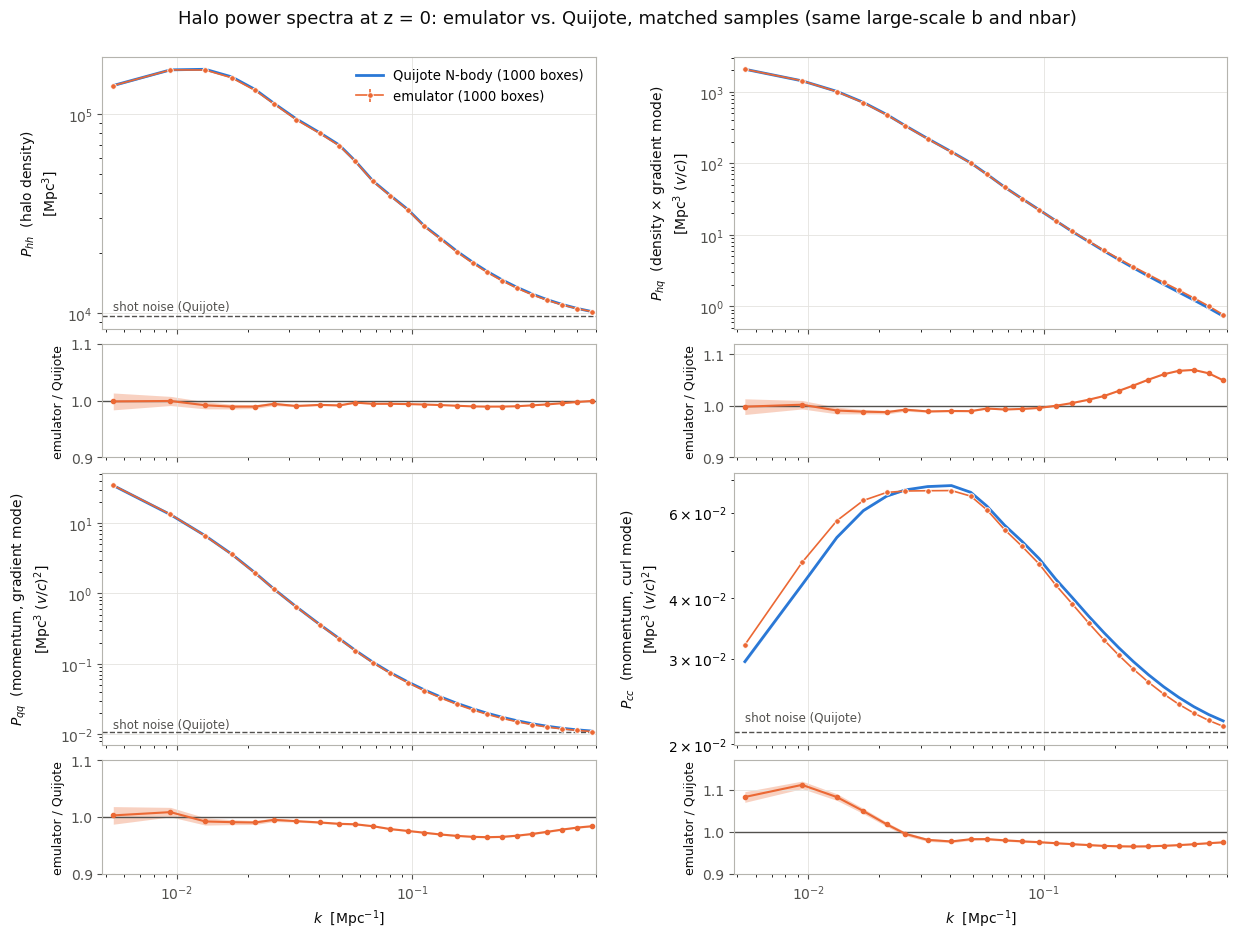

In [5]:
plot_spectra(data['emulator']['matched'], data['quijote']['matched'],
             'Halo power spectra at z = 0: emulator vs. Quijote, matched samples (same large-scale b and nbar)')

## Correlation coefficient and residual field

The residual field $r = h - b\,v = h - b\,(k/faH)\,q$ removes from the halo density the part predicted by the
velocity-inferred density $v$ (equal to the matter density in linear theory). $b$ minimizes the power of $r$ at
$k <$ `KFIT`; it is the halo bias, measured without sample variance. On large scales, where linear theory holds,
$P_{rr}$ is flat: the stochasticity of the halos relative to the velocity field. The middle panel shows
$c(k) = P_{hv}/P_{vv}$, the coefficient that minimizes $P_{rr}$ in each $k$-bin separately: it is constant only at
$k \lesssim 0.02$ Mpc$^{-1}$, so $b$ is fit there.

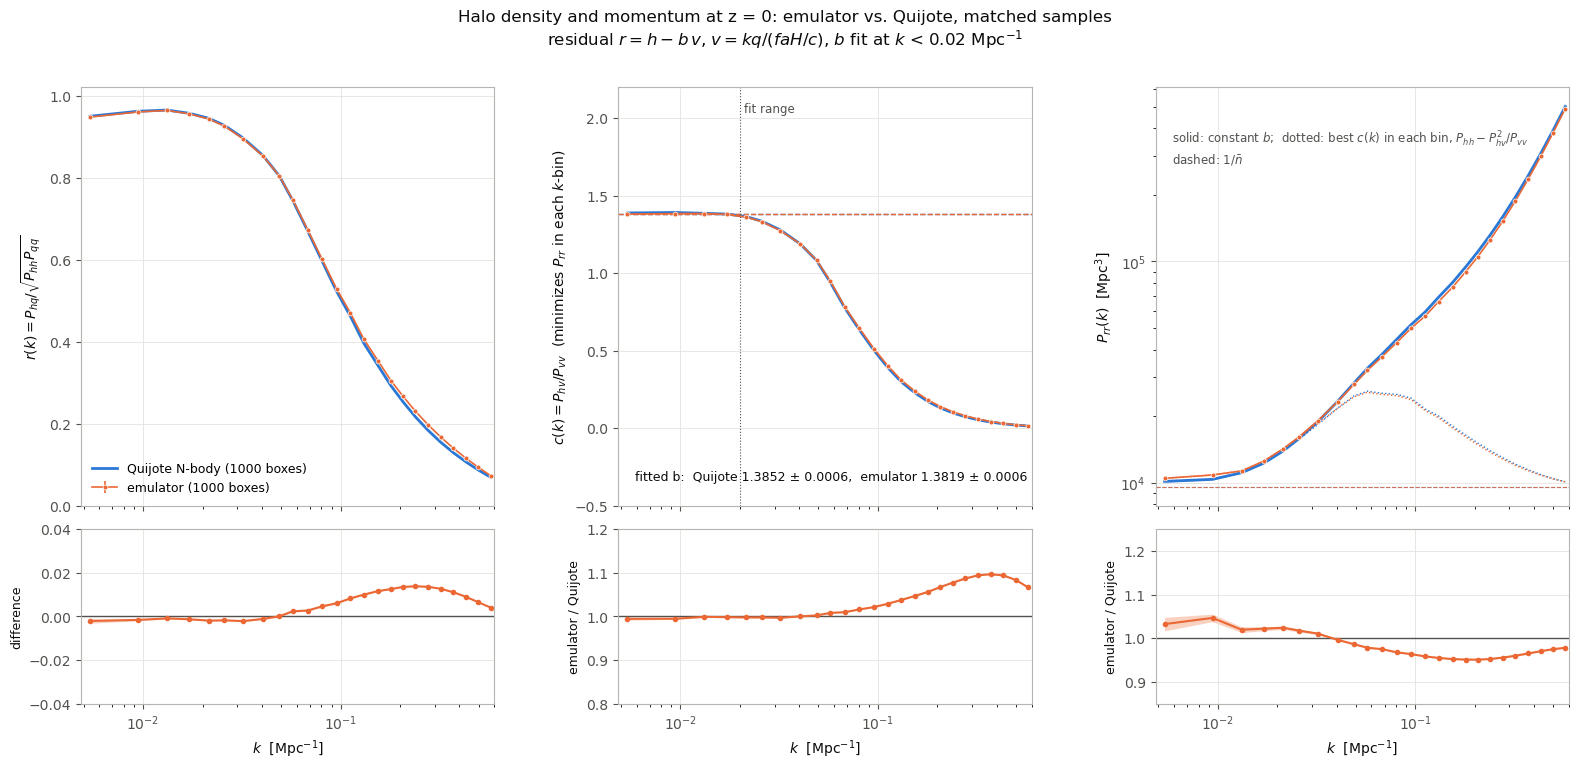

quijote  b vs. k_fit: 0.01: 1.3914,  0.02: 1.3852,  0.03: 1.3465,  0.04: 1.2968,  0.05: 1.2391
emulator b vs. k_fit: 0.01: 1.3839,  0.02: 1.3819,  0.03: 1.3428,  0.04: 1.2937,  0.05: 1.2378


In [6]:
plot_residual(data['emulator']['matched'], data['quijote']['matched'],
              f'Halo density and momentum at z = 0: emulator vs. Quijote, matched samples\n'
              f'residual $r = h - b\\,v$, $v = kq/(faH/c)$, $b$ fit at $k$ < {KFIT} Mpc$^{{-1}}$')

## Covariance of $P_{hh}$

The covariance of $P_{hh}(k)$ in bins of width `COV_WIDTH` $k_f$ up to `COV_KMAX`. Each correlation coefficient
estimated from $N$ simulations has noise $\approx 1/\sqrt{N}$, independent of the binning, while the non-Gaussian
correlations grow with the bin width (the Gaussian part of the covariance falls as $1/N_{\rm modes}$); bins of
$3$–$4\,k_f$ are a compromise. The first panel shows the variance relative to the Gaussian prediction
$2\bar P^2/N_{\rm modes}$ (with $\bar P$ including shot noise). Errors are from bootstrap resampling of the simulations.

The matched samples are compared: dividing the covariance by $\bar P(k)\,\bar P(k')$ removes the dependence of its
Gaussian part on $b$ and $\bar n$, but not of its non-Gaussian part.

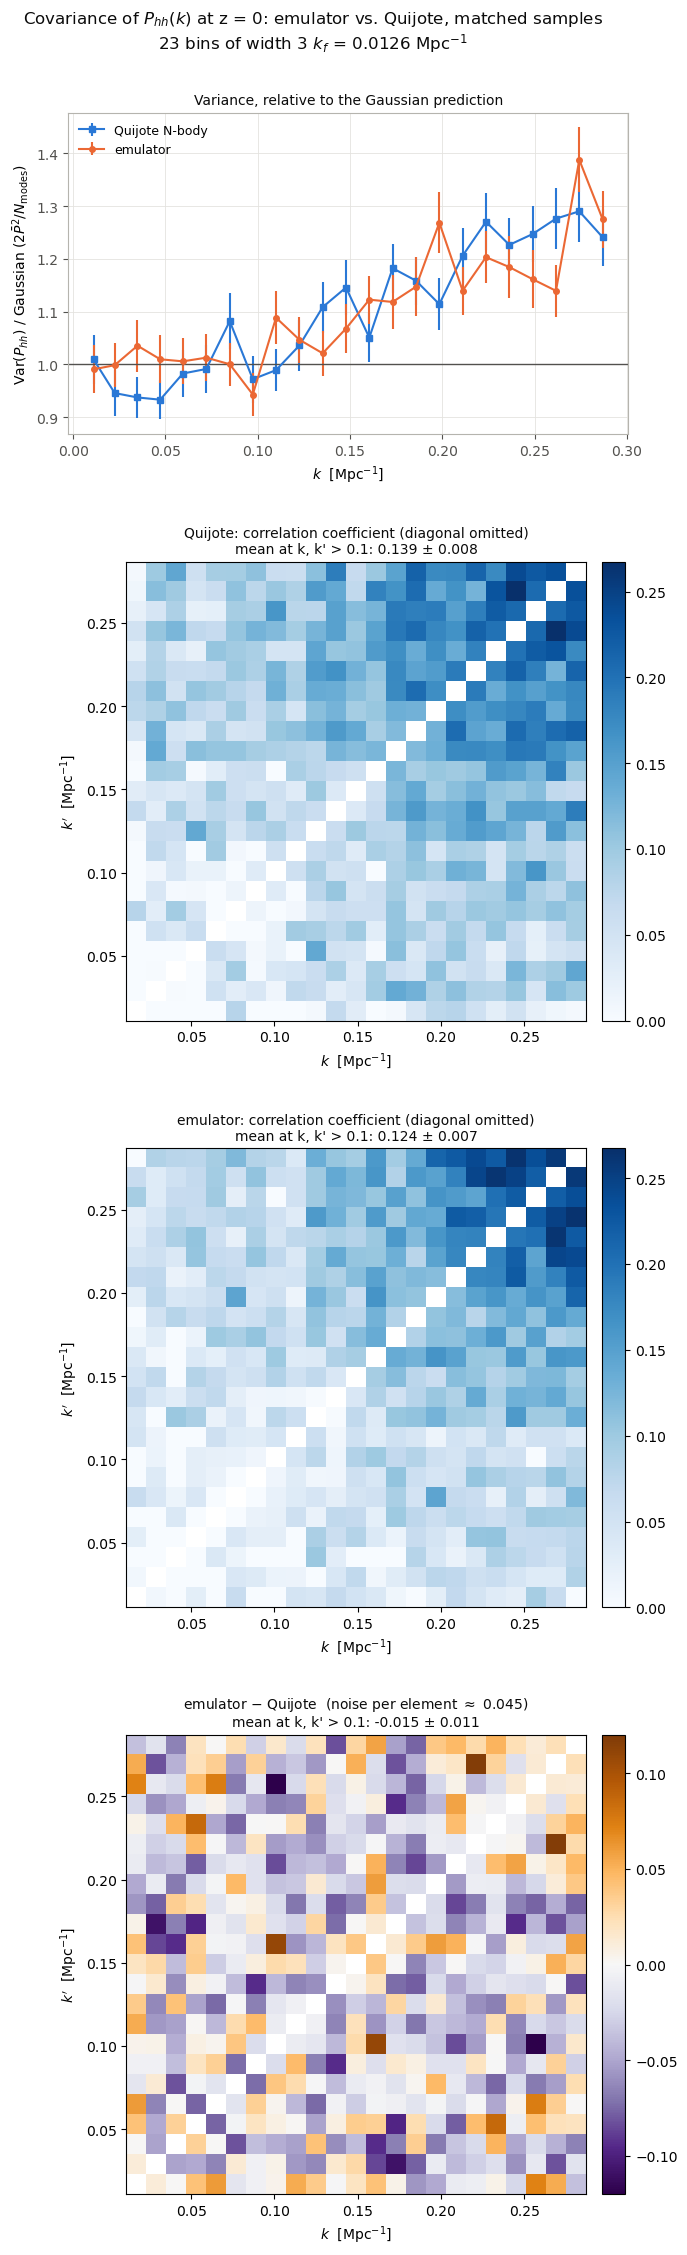

In [7]:
plot_covariance(data['emulator']['matched'], data['quijote']['matched'],
                'Covariance of $P_{hh}(k)$ at z = 0: emulator vs. Quijote, matched samples')

## Summary

Emulator / Quijote ratios of the mean spectra of the matched samples, averaged over ranges of $k$. "P_hh-shot"
subtracts the shot noise $1/\bar n$ from both; $r$ is the correlation coefficient of $h$ and $q$; $P_{rr}$ uses each
simulation set's own $b$.

In [8]:
ratio_table(data['emulator']['matched'], data['quijote']['matched'])

halos per box: emulator 343584, Quijote 343651;  b: emulator 1.3819, Quijote 1.3852
k range [1/Mpc]   P_hh   P_hh-shot   P_hq    P_qq    P_cc    r_emu-r_Q   P_rr
[0.005, 0.02)     0.992  0.992       0.993   0.999   1.066   -0.0017     1.025
[ 0.02, 0.05)     0.992  0.991       0.990   0.991   0.982   -0.0016     0.999
[ 0.05,  0.1)     0.994  0.993       0.994   0.981   0.978   +0.0038     0.969
[  0.1,  0.2)     0.991  0.983       1.011   0.967   0.968   +0.0113     0.952
[  0.2,  0.4)     0.992  0.965       1.054   0.970   0.966   +0.0124     0.961


## Appendix A: results without sample matching

The same comparisons for all the halos with ≥ 20 particles in each catalog, without the matching of the bias and the
number density. Remember that the two sets of catalogs still differ in their FoF linking length: **0.18 for the
emulator, 0.2 for Quijote**, chosen so that the mass functions agree (below).

### Mass function

The mass function $dn/d\ln M$ of all the halos, with $M = N_{\rm part}\, m_{\rm part}$ for both (the particle mass is
the same). Halos with the conventional linking length 0.2 would be 6–7% more massive in the emulator than in Quijote.
With 0.18, the two mass functions agree to within 3% from $5 \times 10^{13}$ to $1.5 \times 10^{15}\,M_\odot$ (50 to
1500 particles). The emulator has ~5% fewer of the smallest halos (20–40 particles), and 5–12% fewer of the rare
halos above $1.5 \times 10^{15}\,M_\odot$.

The dotted line is the threshold of the emulator's matched sample. Matching the bias removes the emulator's halos
below it, although the two mass functions differ by only ~5% there: at the same mass, the emulator's halos are less
biased than Quijote's.

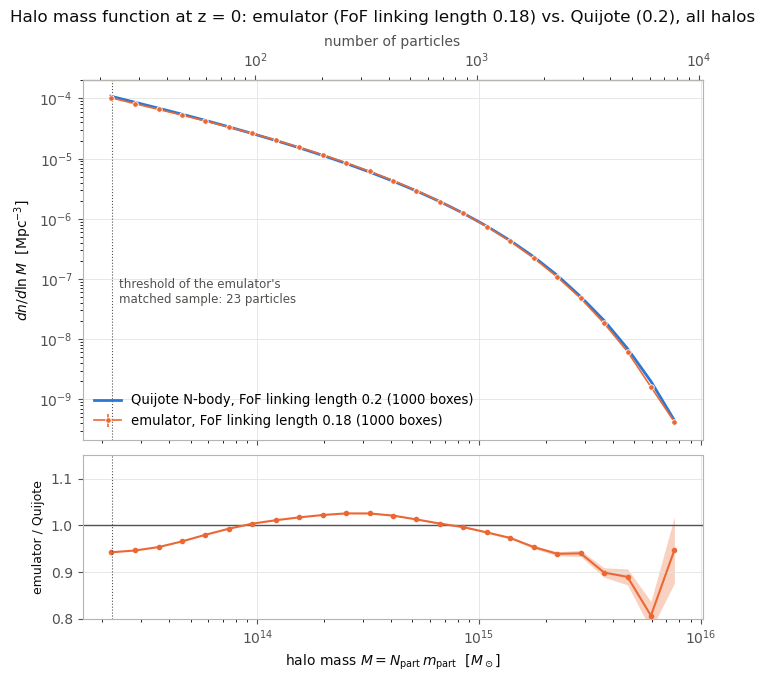

In [9]:
plot_hmf(data['emulator']['all'], data['quijote']['all'],
         'Halo mass function at z = 0: emulator (FoF linking length 0.18) vs. Quijote (0.2), all halos')

### Power spectra

Without matching, the emulator's halos are less biased and 3% fewer, so $P_{hh}$ is lower on large scales, and its shot
noise higher.

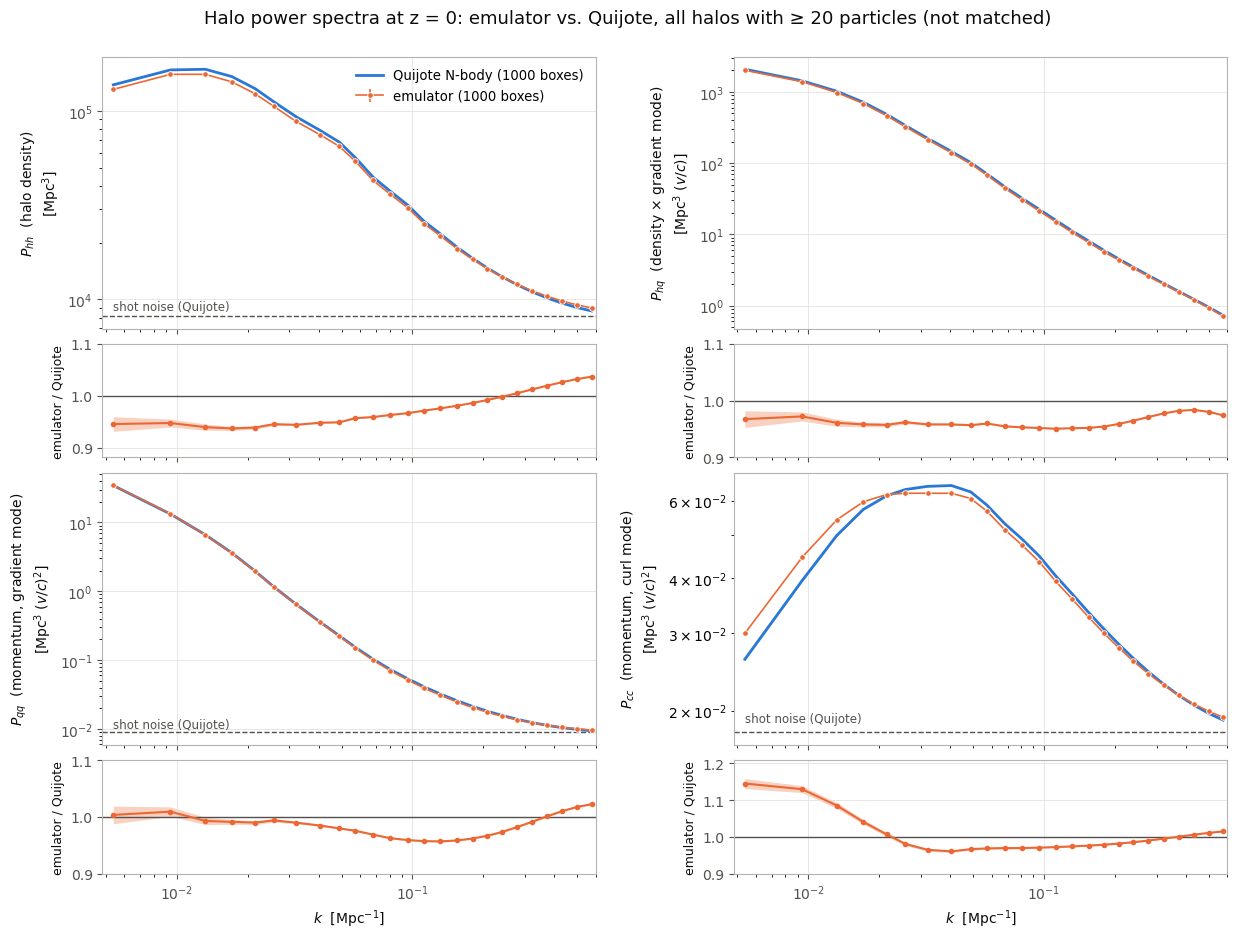

In [10]:
plot_spectra(data['emulator']['all'], data['quijote']['all'],
             'Halo power spectra at z = 0: emulator vs. Quijote, all halos with ≥ 20 particles (not matched)')

### Correlation coefficient and residual field

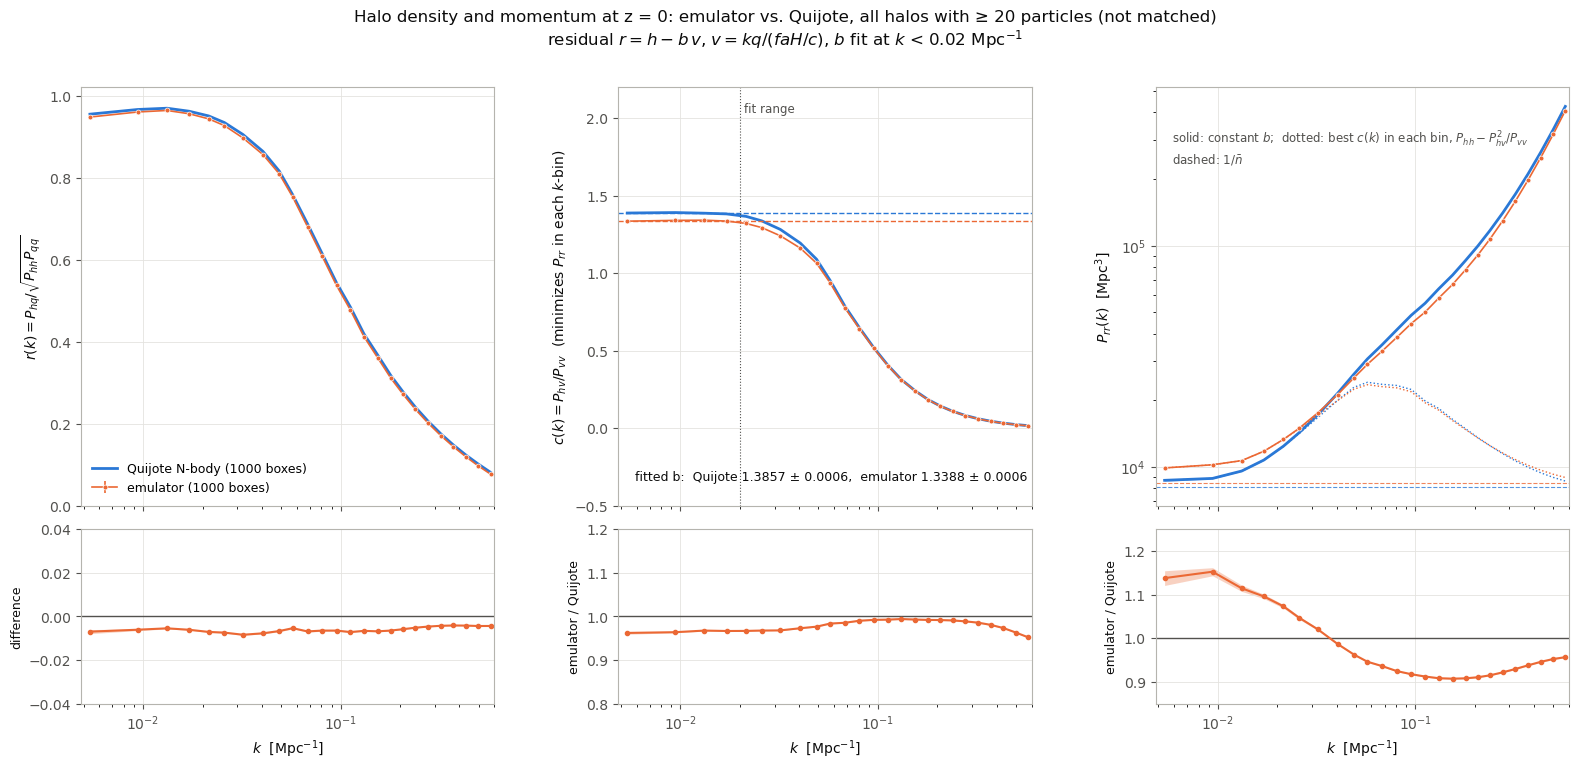

quijote  b vs. k_fit: 0.01: 1.3909,  0.02: 1.3857,  0.03: 1.3480,  0.04: 1.2997,  0.05: 1.2435
emulator b vs. k_fit: 0.01: 1.3400,  0.02: 1.3388,  0.03: 1.3033,  0.04: 1.2585,  0.05: 1.2070


In [11]:
plot_residual(data['emulator']['all'], data['quijote']['all'],
              f'Halo density and momentum at z = 0: emulator vs. Quijote, all halos with ≥ 20 particles (not matched)\n'
              f'residual $r = h - b\\,v$, $v = kq/(faH/c)$, $b$ fit at $k$ < {KFIT} Mpc$^{{-1}}$')

### Summary, without matching

In [12]:
ratio_table(data['emulator']['all'], data['quijote']['all'])

halos per box: emulator 393517, Quijote 406754;  b: emulator 1.3388, Quijote 1.3857
k range [1/Mpc]   P_hh   P_hh-shot   P_hq    P_qq    P_cc    r_emu-r_Q   P_rr
[0.005, 0.02)     0.940  0.935       0.963   0.999   1.065   -0.0061     1.110
[ 0.02, 0.05)     0.946  0.937       0.958   0.988   0.966   -0.0081     0.994
[ 0.05,  0.1)     0.962  0.943       0.954   0.967   0.969   -0.0067     0.926
[  0.1,  0.2)     0.981  0.942       0.952   0.959   0.976   -0.0070     0.908
[  0.2,  0.4)     1.011  0.950       0.973   0.989   0.994   -0.0049     0.931
